# 03 - Temporal baseline experiments

**Question:** Does adding customer information improve prediction of a repeat purchase within 90 days?

We compare two versions of logistic regression:
1. Transaction and purchase-history variables only.
2. The same variables plus four customer attributes selected in Notebook 02.

Both use the same chronological split and a 90-day gap. We select the version with the higher validation **F1-score for class 1**, the competition metric confirmed in the Evaluation screenshot supplied by the group. We use the default probability threshold of 0.5 for both models. An exact tie favours the simpler transaction-only version.

This notebook is an intermediate baseline. The final project still needs at least five algorithms covered in class, further feature-selection experiments, optimisation and an open-ended section. Group contributions and the abstract belong in the group's main deliverable.

## 3.1 Imports and file locations

Run this notebook from the project root or its `notebooks` folder. The CSV files must be in the project's `data` folder. We use pandas for tables, matplotlib for plots, and scikit-learn for preprocessing, modelling and evaluation.

In [25]:
from pathlib import Path
print(Path.cwd())


C:\Users\mmart\Documents\ML_Group_04\notebooks


In [10]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    f1_score, precision_score, recall_score, accuracy_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

DATA_DIR = Path('data')
if not DATA_DIR.is_dir():
    DATA_DIR = Path('..') / 'data'
if not DATA_DIR.is_dir():
    raise FileNotFoundError('Run from the project root or notebooks folder.')

OUTPUT_DIR = DATA_DIR.parent / 'output' / 'notebook03'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TARGET = 'repeat_purchase_90d'
THRESHOLD = 0.5

print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)

pandas: 3.0.3
scikit-learn: 1.9.0


**Justification:** recording versions helps reproduce the results. A threshold of 0.5 means that a predicted repeat-purchase probability of at least 50% becomes class 1. We fix this before evaluating either model; it is not necessarily the best threshold for F1.

## 3.2 Load and check the data

The original CSV files are read without changing them. `ID` identifies a purchase row; `customer_id` identifies the customer and links to the client table.

In [11]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
clients = pd.read_csv(DATA_DIR / 'clientes.csv')
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')

assert train[TARGET].notna().all()
assert set(train[TARGET].unique()) == {0, 1}
assert TARGET not in test.columns
assert train.drop(columns=TARGET).columns.equals(test.columns)
assert train['ID'].is_unique and test['ID'].is_unique
assert set(train['ID']).isdisjoint(test['ID'])
assert sample.columns.tolist() == ['ID', TARGET]
assert sample['ID'].equals(test['ID'])

print('Train:', train.shape)
print('Test:', test.shape)
print('Clients:', clients.shape)
print('All input checks passed.')

Train: (6534, 39)
Test: (986, 38)
Clients: (1143, 13)
All input checks passed.


**Conclusion:** train contains 6,534 purchases and the target; test contains 986 purchases without the target. Predictor columns match, row IDs are unique, and the sample submission uses the same test IDs in the same order. An `assert` stops execution if a required condition is false, preventing us from continuing with misaligned data.

## 3.3 Apply the cleaning decisions from Notebook 01

First, exclude the 65 rows whose transaction predictors are all missing. They also lack a purchase date. We exclude the same rows from both experiments to keep the comparison fair. These rows could receive customer information after joining, so exclusion is a baseline decision, not proof that predictions are impossible.

Convert invalid values only in the four audited historical fields. Negative time intervals are invalid. For historical monetary fields, we follow the group's current assumption that negative values are invalid; this should be revisited if returns or credit notes can explain them. Exact values of 1,000,000,000 were identified as suspected corruption in Notebook 01. Ordinary large values are retained.

In [12]:
transaction_columns = train.columns.drop([TARGET, 'ID', 'customer_id'])
empty_rows = train[transaction_columns].isna().all(axis=1)
dates = pd.to_datetime(train['purchase_date'], errors='coerce')
usable_rows = (~empty_rows) & dates.notna()

data = train.loc[usable_rows].copy()
data['purchase_date'] = dates.loc[usable_rows]

print('Original purchases:', len(train))
print('Almost-empty rows excluded:', empty_rows.sum())
print('Other rows with missing dates excluded:', ((~empty_rows) & dates.isna()).sum())
print('Purchases available for the experiments:', len(data))

Original purchases: 6534
Almost-empty rows excluded: 65
Other rows with missing dates excluded: 0
Purchases available for the experiments: 6469


**Conclusion:** 6,469 purchases remain. Removing rows is based on predictor availability, not their target. The denominator for the split percentages below is these 6,469 eligible purchases. Test rows will not be dropped.

In [13]:
# One small function applies exactly the same corrections to train and test.
def clean_history(frame):
    cleaned = frame.copy()

    for column in ['days_since_previous_purchase', 'prior_mean_gap_days']:
        invalid = cleaned[column] < 0
        cleaned.loc[invalid, column] = float('nan')

    for column in ['prior_mean_purchase_value', 'spend_365d']:
        invalid = (cleaned[column] < 0) | (cleaned[column] == 1_000_000_000)
        cleaned.loc[invalid, column] = float('nan')

    return cleaned

before_cleaning = data.copy()
data = clean_history(data)
test_clean = clean_history(test)

checked_columns = [
    'days_since_previous_purchase', 'prior_mean_gap_days',
    'prior_mean_purchase_value', 'spend_365d'
]
new_missing = data[checked_columns].isna().sum() - before_cleaning[checked_columns].isna().sum()
display(new_missing.rename('Invalid entries changed to missing').to_frame())

,Invalid entries changed to missing
days_since_previous_purchase,16
prior_mean_gap_days,16
prior_mean_purchase_value,32
spend_365d,30


**Conclusion:** the table reports only values newly changed to missing, rather than counting existing missing values again. Other information in these rows is preserved. This correction uses predefined rules; it does not estimate anything from validation or test. Missing values will be imputed inside each model's training pipeline.

## 3.4 Temporal 80/20 split with a 90-day gap

Sort the purchases by date and use the date at the 80% position to start validation. Keep all purchases on that date together. From the earlier purchases, remove the 90 days immediately before validation.

Why the gap? A purchase's target describes the following 90 days. Its complete target window must finish before validation starts. We therefore train on dates strictly earlier than validation start minus 90 days. We do not perform a random split.

In [14]:
# Keep the purchase order; sort a separate date list to find the cut.
data = data.reset_index(drop=True)
ordered_dates = data['purchase_date'].sort_values().reset_index(drop=True)

cut_position = int(len(data) * 0.80)
validation_start = ordered_dates.iloc[cut_position]
training_limit = validation_start - pd.Timedelta(days=90)

training_rows = data['purchase_date'] < training_limit
validation_rows = data['purchase_date'] >= validation_start
gap_rows = (~training_rows) & (~validation_rows)

assert training_rows.sum() + gap_rows.sum() + validation_rows.sum() == len(data)
assert data.loc[training_rows, 'purchase_date'].max() + pd.Timedelta(days=90) < validation_start
assert data.loc[training_rows, TARGET].nunique() == 2
assert data.loc[validation_rows, TARGET].nunique() == 2

split_summary = pd.DataFrame({
    'Partition': ['Training', '90-day gap', 'Validation'],
    'Purchases': [training_rows.sum(), gap_rows.sum(), validation_rows.sum()]
})
split_summary['Percentage of eligible data'] = 100 * split_summary['Purchases'] / len(data)

display(split_summary.round(2))
print('Training: dates before', training_limit.date())
print('Gap: from', training_limit.date(), 'to the day before', validation_start.date())
print('Validation: dates from', validation_start.date())

,Partition,Purchases,Percentage of eligible data
0,Training,5024,77.66
1,90-day gap,147,2.27
2,Validation,1298,20.06


Training: dates before 2023-03-19
Gap: from 2023-03-19 to the day before 2023-06-17
Validation: dates from 2023-06-17


**Conclusion:** training contains **5,024 purchases (77.66%)**, validation contains **1,298 (20.06%)**, and the gap excludes **147 (2.27%)**. Training is before 19 March 2023; validation starts on 17 June 2023. The initial cut is approximately 80/20, but training becomes smaller after removing the gap. Purchases sharing the cut date explain why validation is not exactly 20%.

These percentages exclude the 65 undated rows. Relative to all 6,534 original rows, training is 76.89%, the gap 2.25%, validation 19.87%, and undated exclusions 0.99%.

In [15]:
print('Training repeat-purchase rate:', round(data.loc[training_rows, TARGET].mean(), 4))
print('Validation repeat-purchase rate:', round(data.loc[validation_rows, TARGET].mean(), 4))

training_customers = set(data.loc[training_rows, 'customer_id'])
validation_customers = set(data.loc[validation_rows, 'customer_id'])
print('Customers shared by training and validation:',
      len(training_customers.intersection(validation_customers)))

Training repeat-purchase rate: 0.5498
Validation repeat-purchase rate: 0.6032
Customers shared by training and validation: 194


**Interpretation:** class proportions can change over time, which affects precision and F1. Shared customers are allowed: predicting later purchases of known customers is part of this task. This split does not separately measure performance on entirely new customers. The historical variables are assumed to use only information available at each purchase; a gap cannot repair a predictor that already contains future information.

## 3.5 Create the two feature sets

Keep the transaction variables identified in Notebook 01, excluding `ID`, `customer_id`, `purchase_date` and the target. Date is used only to define the split. Retain `random_noise` in both versions for now; a later feature-selection experiment should test its removal.

Add only `country_or_region`, `commercial_region`, `island` and `customer_since_year`, as selected in Notebook 02. The entry year is categorical. We assume client attributes were available and stable at the time of each purchase. Checking entry year against purchase year does not prove the historical availability of current region or island.

In [16]:
client_features = [
    'country_or_region', 'commercial_region', 'island', 'customer_since_year'
]

assert clients['customer_id'].is_unique
assert clients['customer_id'].notna().all()
assert data['customer_id'].isin(clients['customer_id']).all()
assert test_clean['customer_id'].isin(clients['customer_id']).all()

data_clients = data.merge(
    clients[['customer_id'] + client_features],
    on='customer_id', how='left', validate='many_to_one', sort=False
)
test_clients = test_clean.merge(
    clients[['customer_id'] + client_features],
    on='customer_id', how='left', validate='many_to_one', sort=False
)

assert data_clients['ID'].equals(data['ID'])
assert test_clients['ID'].equals(test_clean['ID'])

data_clients['customer_since_year'] = data_clients['customer_since_year'].astype(str)
test_clients['customer_since_year'] = test_clients['customer_since_year'].astype(str)

transaction_features = test.columns.drop(['ID', 'customer_id', 'purchase_date']).tolist()
enriched_features = transaction_features + client_features

print('Transaction-only features:', len(transaction_features))
print('Client-enriched features:', len(enriched_features))
print('Purchase IDs and their order are preserved after both joins.')

Transaction-only features: 35
Client-enriched features: 39
Purchase IDs and their order are preserved after both joins.


**Conclusion:** both experiments use the same purchase IDs and targets. The first uses 35 predictors, and the second uses 39. The four added columns are the only intended difference. `many_to_one` checks that the customer table cannot multiply purchases. This comparison tests one feature-set decision; it does not complete the feature-selection requirements for the final project.

## 3.6 Prepare the training and validation tables

Use the same row masks for both versions. `X` contains predictors and `y` contains the target. The masks come from dates, not from target values.

In [17]:
X_train = data.loc[training_rows, transaction_features]
X_valid = data.loc[validation_rows, transaction_features]

X_train_clients = data_clients.loc[training_rows, enriched_features]
X_valid_clients = data_clients.loc[validation_rows, enriched_features]

y_train = data.loc[training_rows, TARGET]
y_valid = data.loc[validation_rows, TARGET]

assert X_train.index.equals(X_train_clients.index)
assert X_valid.index.equals(X_valid_clients.index)

print('Transaction-only training and validation:', X_train.shape, X_valid.shape)
print('Client-enriched training and validation:', X_train_clients.shape, X_valid_clients.shape)

Transaction-only training and validation: (5024, 35) (1298, 35)
Client-enriched training and validation: (5024, 39) (1298, 39)


**Conclusion:** training and validation have identical row counts and row alignment in both versions. This avoids attributing a score difference to using different purchases.

## 3.7 Build a simple preprocessing and modelling pipeline

We need two different types of preparation:
- **Numeric variables:** fill missing values with the training median, add indicators for variables missing during training, and standardise their scale.
- **Categorical variables:** represent missing values as `Missing` and use one-hot encoding. Ignore unseen categories so validation/test can still be transformed.

A **Pipeline** performs these steps in order and then fits logistic regression. A **ColumnTransformer** sends numeric and categorical columns through their respective steps. Keeping these objects is useful even for a first baseline: calling `fit` on training data learns medians, scales and categories there; calling `predict` on validation does not learn them again.

The small function below builds a fresh pipeline for each feature set, avoiding duplicated preprocessing code. `C=1` fixes regularisation strength; `lbfgs` is the solver. The high iteration limit allows convergence; we are not searching for the best parameters.

In [18]:
def make_model(X):
    numeric_columns = X.select_dtypes(include='number').columns.tolist()
    categorical_columns = X.select_dtypes(exclude='number').columns.tolist()

    numeric_steps = Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', StandardScaler())
    ])

    categorical_steps = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    preparation = ColumnTransformer([
        ('numeric', numeric_steps, numeric_columns),
        ('categorical', categorical_steps, categorical_columns)
    ])

    model = Pipeline([
        ('preparation', preparation),
        ('classifier', LogisticRegression(C=1.0, solver='lbfgs', max_iter=10000))
    ])
    return model

print('Model-building function ready. No fitting has happened yet.')

Model-building function ready. No fitting has happened yet.


**Justification:** standardisation makes the regularisation less dependent on measurement units. One-hot encoding avoids treating category names as numbers. Missing indicators preserve information that a value was absent; an indicator is created only if that variable was missing during fitting. No class weights or resampling are used in this initial baseline.

## 3.8 Train the two logistic regression models

Use the same settings and a probability threshold of 0.5. The only experimental change is the four extra customer variables.

In [19]:
transaction_model = make_model(X_train)
transaction_model.fit(X_train, y_train)
transaction_probability = transaction_model.predict_proba(X_valid)[:, 1]
transaction_prediction = (transaction_probability >= THRESHOLD).astype(int)

client_model = make_model(X_train_clients)
client_model.fit(X_train_clients, y_train)
client_probability = client_model.predict_proba(X_valid_clients)[:, 1]
client_prediction = (client_probability >= THRESHOLD).astype(int)

assert transaction_model['classifier'].n_iter_.max() < 10000
assert client_model['classifier'].n_iter_.max() < 10000
print('Both models fitted without reaching the iteration limit.')

Both models fitted without reaching the iteration limit.


**Conclusion:** both models produced predictions for the same 1,298 validation purchases. `predict_proba(... )[:, 1]` selects the estimated probability of class 1; comparison with 0.5 converts it to a binary prediction. The convergence checks prevent reporting a model that reached its iteration limit.

## 3.9 Compare F1, precision and recall

F1 for class 1 is the primary selection metric. Precision shows how often predicted returners actually return; recall shows how many actual returners are found. Accuracy and ROC-AUC provide additional context. ROC-AUC uses probabilities but does not select the winner.

We also include a model that always predicts class 1. F1 can be fairly high for this trivial rule, so it provides an important reference.

In [20]:
dummy_model = DummyClassifier(strategy='constant', constant=1)
dummy_model.fit(X_train, y_train)
dummy_prediction = dummy_model.predict(X_valid)
dummy_probability = dummy_model.predict_proba(X_valid)[:, 1]

# The same small function calculates the same metrics for every model.
def evaluate_model(name, prediction, probability):
    return {
        'Model': name,
        'F1': f1_score(y_valid, prediction, zero_division=0),
        'Precision': precision_score(y_valid, prediction, zero_division=0),
        'Recall': recall_score(y_valid, prediction, zero_division=0),
        'Accuracy': accuracy_score(y_valid, prediction),
        'ROC-AUC': roc_auc_score(y_valid, probability)
    }

results = pd.DataFrame([
    evaluate_model('Always positive', dummy_prediction, dummy_probability),
    evaluate_model('Transactions', transaction_prediction, transaction_probability),
    evaluate_model('Transactions + clients', client_prediction, client_probability)
]).set_index('Model')

display(results.round(4))
print('Precision measures the reliability of positive predictions; recall measures coverage.')

,F1,Precision,Recall,Accuracy,ROC-AUC
Model,,,,,
Always positive,0.7525,0.6032,1.0000,0.6032,0.5000
Transactions,0.7525,0.7971,0.7126,0.7173,0.7840
Transactions + clients,0.7539,0.7986,0.7139,0.7188,0.7883


Precision measures the reliability of positive predictions; recall measures coverage.


**Interpretation:** always predicting a repeat purchase gives recall of 1 but lower precision. The logistic models sacrifice recall to obtain higher precision and better accuracy. F1 combines precision and recall, so better accuracy or ROC-AUC does not automatically mean a large improvement in F1. `zero_division=0` defines the metric safely if a model predicts no positive cases.

In [21]:
transaction_f1 = results.loc['Transactions', 'F1']
client_f1 = results.loc['Transactions + clients', 'F1']
f1_difference = client_f1 - transaction_f1

if client_f1 > transaction_f1:
    selected_version = 'Transactions + clients'
else:
    selected_version = 'Transactions'

print('Selected version:', selected_version)
print('F1 difference from adding clients:', round(f1_difference, 6))
print('Difference in percentage points:', round(100 * f1_difference, 3))
print('Selected F1:', round(results.loc[selected_version, 'F1'], 4))
print('Always-positive F1:', round(results.loc['Always positive', 'F1'], 4))

Selected version: Transactions + clients
F1 difference from adding clients: 0.001349
Difference in percentage points: 0.135
Selected F1: 0.7539
Always-positive F1: 0.7525


**Conclusion:** the printed comparison applies our rule automatically. In this execution, customer enrichment improves F1 by about **0.00135**, or **0.135 percentage points**. That is a very small difference. The transaction-only model is also almost tied with the always-positive baseline on F1. We must not describe this as a strong improvement or proof of statistical significance.

The selected model is a provisional choice for this baseline, not necessarily the best final solution. Selecting a feature set on this holdout means its reported score is no longer an independent final estimate. We do not repeatedly adjust features or the probability threshold using this validation set.

## 3.10 Inspect the classification errors

In each confusion matrix, rows show the true class and columns show the predicted class. False positives are predicted returners who do not return. False negatives are customers who return but were missed. No commercial costs were supplied, so we cannot claim that 0.5 is the best business threshold.

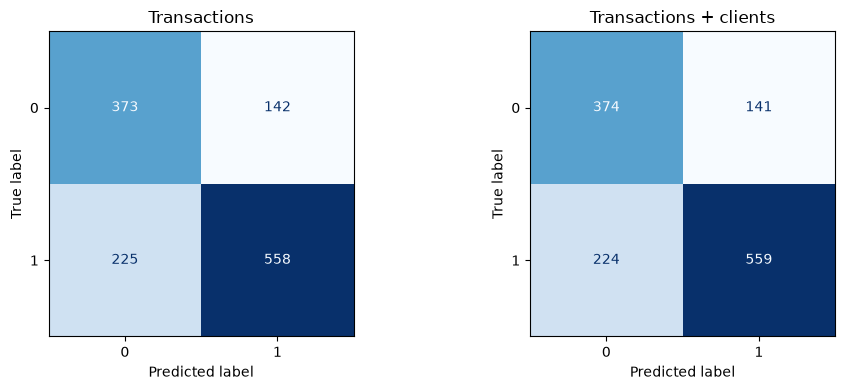

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_valid, transaction_prediction, labels=[0, 1],
    ax=axes[0], cmap='Blues', colorbar=False
)
axes[0].set_title('Transactions')

ConfusionMatrixDisplay.from_predictions(
    y_valid, client_prediction, labels=[0, 1],
    ax=axes[1], cmap='Blues', colorbar=False
)
axes[1].set_title('Transactions + clients')

plt.tight_layout()
plt.show()

**Conclusion:** in the current execution, the transaction model has 142 false positives and 225 false negatives; the enriched model has 141 and 224 respectively. Enrichment corrects only a small number of errors overall. This supports the cautious interpretation of the small F1 change, rather than claiming a substantial gain.

## 3.11 Refit the selected version and predict test

After recording evaluation, train a fresh pipeline on all 6,469 eligible labelled purchases, including the previously withheld gap and validation purchases. Those rows were excluded for evaluation, not permanently unusable. Their complete 90-day target windows must end before test starts.

The final pipeline learns its preprocessing again from all eligible training purchases. It transforms test without fitting on test. We generate binary classes, preserve every test row, and do not upload anything automatically to Kaggle.

In [23]:
first_test_date = pd.to_datetime(test['purchase_date'], errors='coerce').min()
last_training_date = data['purchase_date'].max()
assert last_training_date + pd.Timedelta(days=90) < first_test_date

if selected_version == 'Transactions + clients':
    X_final = data_clients[enriched_features]
    X_test = test_clients[enriched_features]
else:
    X_final = data[transaction_features]
    X_test = test_clean[transaction_features]

final_model = make_model(X_final)
final_model.fit(X_final, data[TARGET])
assert final_model['classifier'].n_iter_.max() < 10000

test_probability = final_model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= THRESHOLD).astype(int)

print('Final version:', selected_version)
print('Final training purchases:', len(X_final))
print('Last labelled purchase:', last_training_date.date())
print('First test purchase:', first_test_date.date())
print('Number of test predictions:', len(test_prediction))

Final version: Transactions + clients
Final training purchases: 6469
Last labelled purchase: 2025-02-15
First test purchase: 2025-05-24
Number of test predictions: 986


**Conclusion:** all eligible training target windows finish before the first test purchase. The selected pipeline can therefore be refitted on those rows and produce 986 predictions. Refitting does not provide a new validation score; the earlier holdout results remain our evaluation record.

In [24]:
submission = sample[['ID']].copy()
submission[TARGET] = test_prediction

assert len(submission) == len(test)
assert submission['ID'].equals(test['ID'])
assert submission.columns.tolist() == sample.columns.tolist()
assert submission.notna().all().all()
assert set(submission[TARGET].unique()).issubset({0, 1})

submission_path = OUTPUT_DIR / 'submission_logistic_temporal.csv'
submission.to_csv(submission_path, index=False)
saved_submission = pd.read_csv(submission_path)
pd.testing.assert_frame_equal(saved_submission, submission)

results.to_csv(OUTPUT_DIR / 'validation_metrics.csv')
split_summary.to_csv(OUTPUT_DIR / 'temporal_split_summary.csv', index=False)

display(submission.head())
print('Predicted repeat-purchase rate:', round(submission[TARGET].mean(), 4))
print('Submission saved to:', submission_path)
print('CSV read-back check passed.')

,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,0
3,10000020,0
4,10000025,0


Predicted repeat-purchase rate: 0.5832
Submission saved to: ..\output\notebook03\submission_logistic_temporal.csv
CSV read-back check passed.


**Conclusion:** the saved CSV has one binary prediction per test ID, correct column names and the required row order. Reading it back confirms it matches the table in memory. The proportion predicted positive is not accuracy: the true test targets are hidden. The file is ready for the group's Kaggle submission, but no upload has been performed.

## 3.12 Limitations and next steps

- This is one logistic regression baseline with two feature sets and one temporal holdout. The small enrichment gain needs checking across other periods/models.
- Purchases from the same customer are not independent. Shared customers are intentional for this task, but performance on new customers may differ.
- Current customer attributes are assumed historically available; the supplied table does not prove this.
- Excluding undated rows and treating negative monetary histories as invalid are documented assumptions.
- Earlier notebooks explored target relationships using the supplied training data. This holdout is therefore not completely untouched by exploratory decisions.
- Further feature selection, at least five class-covered algorithms and optimisation are still required for the final project. If tuning thresholds or parameters, use inner temporal validation and keep a separate later period for final assessment.
- Any statements containing exact results describe the current execution and must be checked if input data or model settings change.

**Defence checklist:** explain the 90-day gap, the changed training percentage, why both versions use identical rows, why preprocessing is fitted on training only, what precision/recall/F1 mean, why the dummy baseline matters, and why final refitting includes validation rows.

**Provenance:** project guidelines, the cleaning decisions in Notebook 01, customer-feature decisions in Notebook 02, the supplied CSV files and the group-supplied Kaggle Evaluation screenshot confirming F1.